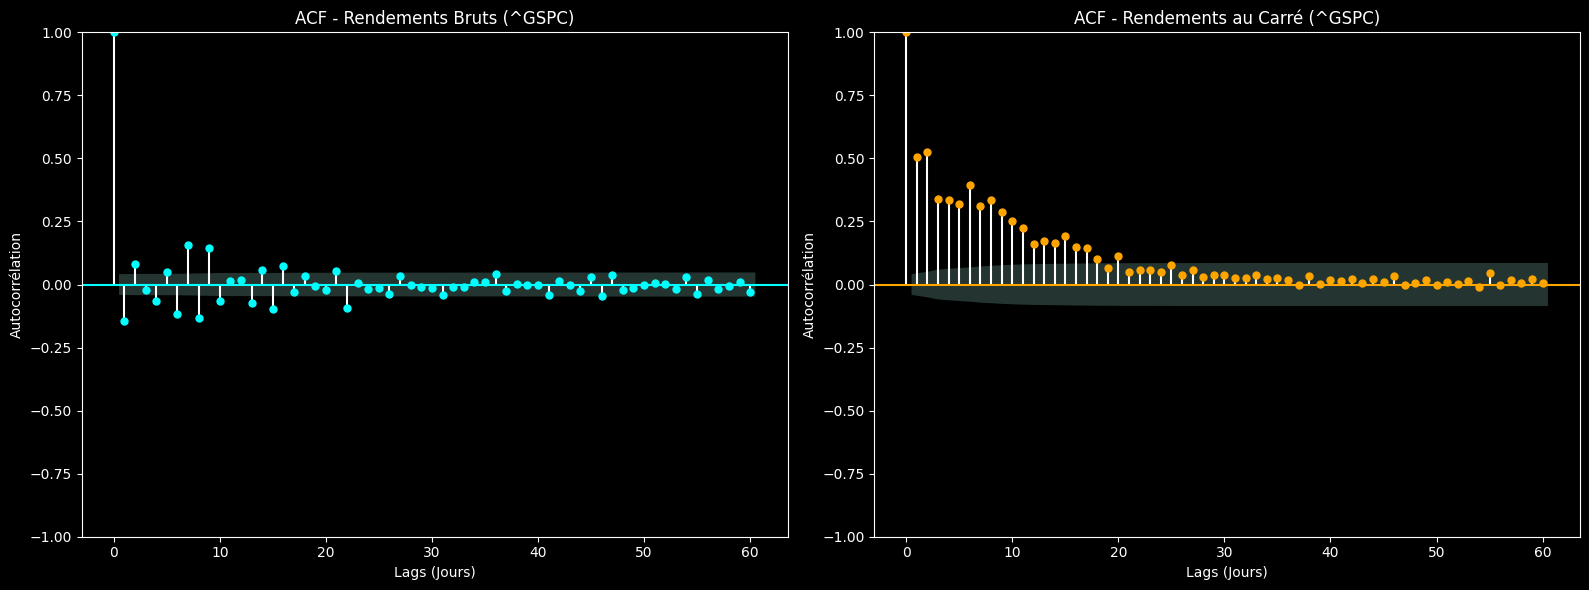

AttributeError: 'DataFrame' object has no attribute 'autocorr'

In [1]:
import pandas as pd
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf

# 1. Récupération des données (ex: SP500)
ticker = "^GSPC" 
data = yf.download(ticker, start="2015-01-01", end="2024-01-01", progress=False)
returns = data['Close'].pct_change().dropna()

# Calcul des rendements au carré (proxy de la variance)
squared_returns = returns ** 2

# 2. Configuration graphique
plt.style.use('dark_background')
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 3. ACF des Rendements Bruts (Espérance mu)
plot_acf(returns, lags=60, ax=axes[0], alpha=0.05, color='cyan')
axes[0].set_title(f"ACF - Rendements Bruts ({ticker})")
axes[0].set_xlabel("Lags (Jours)")
axes[0].set_ylabel("Autocorrélation")

# 4. ACF des Rendements au Carré (Volatilité / Variance)
plot_acf(squared_returns, lags=60, ax=axes[1], alpha=0.05, color='orange')
axes[1].set_title(f"ACF - Rendements au Carré ({ticker})")
axes[1].set_xlabel("Lags (Jours)")
axes[1].set_ylabel("Autocorrélation")

plt.tight_layout()
plt.show()

# 5. Calcul de la demi-vie empirique sur la volatilité (modèle AR(1) simple)
autocorr_1 = squared_returns.autocorr(lag=1)
if autocorr_1 > 0:
    half_life = -np.log(2) / np.log(autocorr_1)
    print(f"Demi-vie estimée de la volatilité : {half_life:.2f} jours")